In [8]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Formatting
## Set variables
colour1 = "royalblue"
colour2 = "red"
colour3 = "goldenrod"

titleFont = 15
subplotFont = 15

# Input variables

## Wind
dataSource = "Wind"

dataDirectory = "Data/windData/"
dataName = "wind_min_b"
plotDirectory = "Plots/WindYearlyPlots/"

#### Details: Yearly, minutely data, bow-shock shifted

### Interpolation
interpolateYJump = 50

## Data analysis
### General
#### Time ranges to investigate
# timeRange = [["1996-01-01 00:00:00", "1997-01-01 00:00:00"]]
# timeRange = [["1996-01-01 00:00:00", "1996-02-01 00:00:00"], ["2023-01-01 00:00:00", "2023-02-01 00:00:00"]]
timeRange = [["1996-01-01 00:00:00", "1996-12-31 23:59:00"], ["2001-01-01 00:00:00", "2001-12-31 23:59:00"]]

#### TotVsw
Variable = "TotVsw"
VariableUnit = "km/s"
#### BMag
# Variable = "BMag"
# Unit = "nT"

### Time series
resamplerate = "1h"
statsResampleRate = "1d"
yLim = [[250, 750],[-50, 2000],[-80, 200], [250, 850], [0, 160]]

### Histograms
# Bins = [1,2,3,4,5,6,7,8,9,10,11,12]
# Histogram = (8,6)

### Steadiness
varThres =  100 # 50, 10**2 = 100, 250

In [2]:
### Places to get and save files
dataTimeframe = ["1996-01-01 00:00", "2025-01-01 00:00"]
start = dataTimeframe[0] # start date of data
end = dataTimeframe[1] # end date of data
filename = "Wind_" + str(start)[0:10] + "-" + str(end)[0:10]+ "_Enriched.csv"

# Read in data

In [4]:
## Read data in
windData = pd.read_csv(filename, index_col=["Unnamed: 0"])

# Set index to datatime type
windData.index = pd.to_datetime(windData.index)

# Plotting

## All data - for getting limits and overview

In [ ]:
#ylims for variable values

## TotVsw
totvsw_ylim_min = [200, 1250]
totvsw_ylim_hour = [200, 1250]

print(totvsw_ylim_hour)

[0, 1250]


In [ ]:
# windData[(windData.index >= beginning) & (windData.index <= ending)].index[0]
# windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]

Timestamp('2024-12-31 23:59:00')

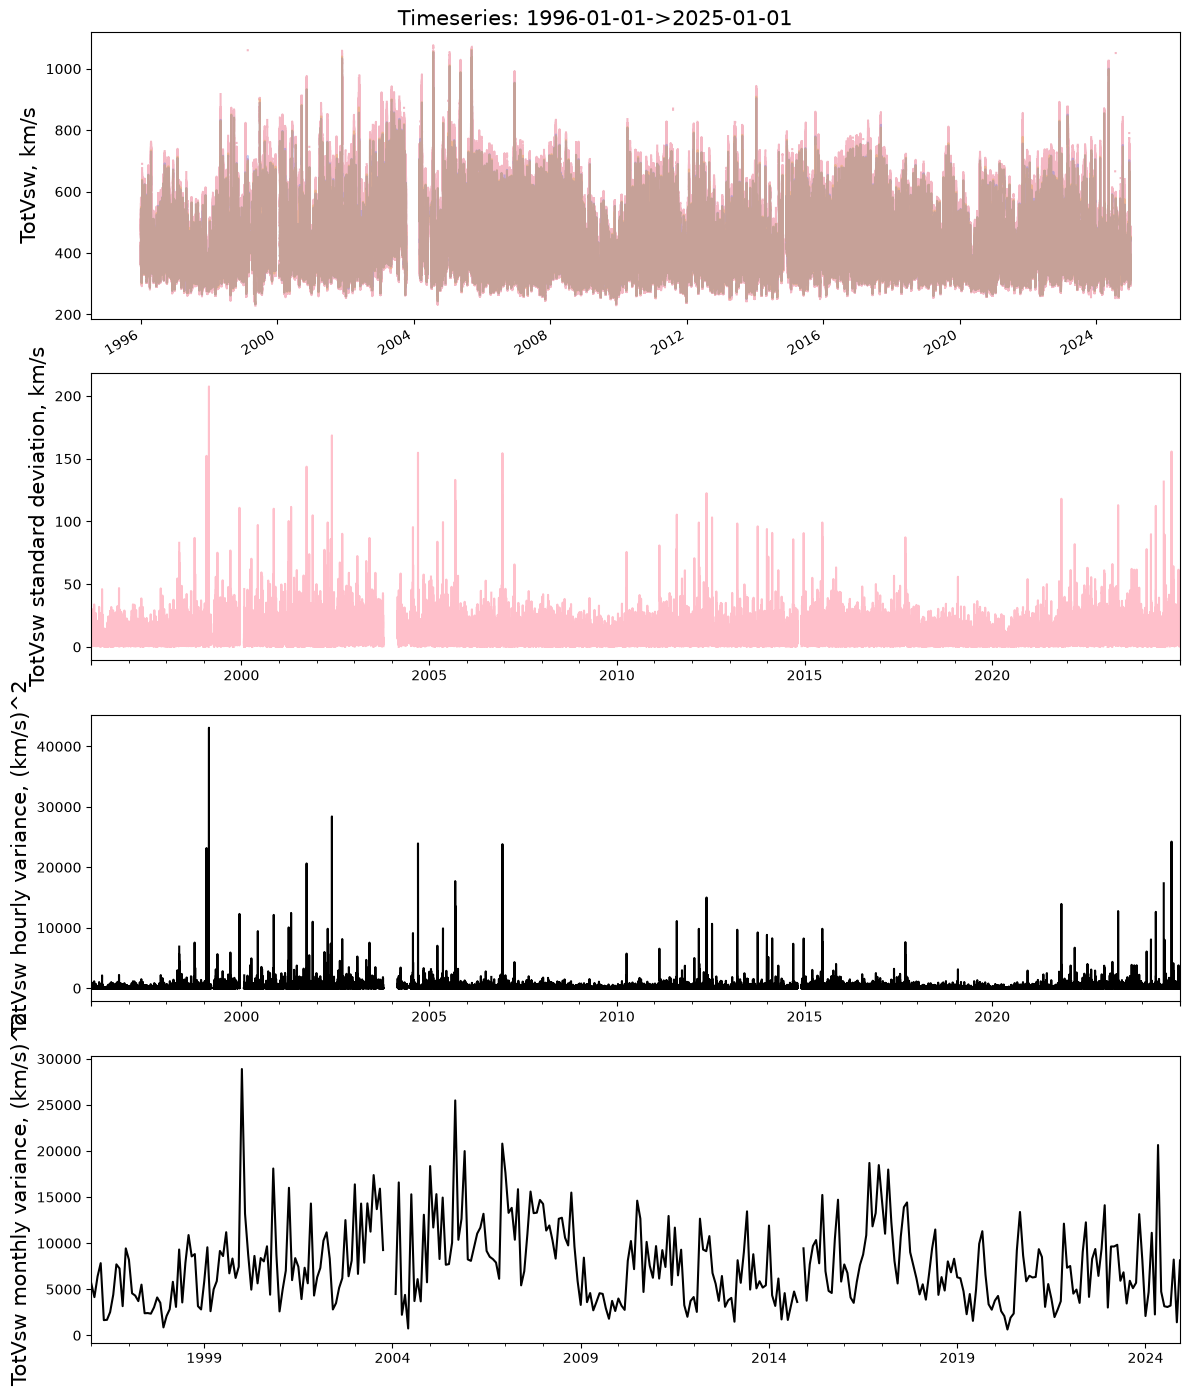

In [17]:
fig, axs = plt.subplots(4,1, figsize = [12,14])#, sharex=True)

beginning = "1996-01-01"
ending = "2025-01-01"
alpha_1 = 0.3

xLim = [windData[(windData.index >= beginning) & (windData.index <= ending)].index[0], windData[(windData.index >= beginning) & (windData.index <= ending)].index[-1]]

windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].plot(ax=axs[0], color = "crimson", label = "Minutely data", alpha = alpha_1)
windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean", alpha = alpha_1)
windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median", alpha = alpha_1)

windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")

windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")

windData[(windData.index >= beginning) & (windData.index <= ending)]["TotVsw"].resample("ME").var().plot(ax=axs[3], color = "black", label = "Hourly var")

axs[0].set_ylabel("TotVsw, km/s" , fontsize = subplotFont)
axs[1].set_ylabel("TotVsw standard deviation, km/s" , fontsize = subplotFont)
axs[2].set_ylabel("TotVsw hourly variance, (km/s)^2" , fontsize = subplotFont)
axs[3].set_ylabel("TotVsw monthly variance, (km/s)^2" , fontsize = subplotFont)
# axs[0].set_ylim([300, 700])
# axs[1].set_ylim([0, 20])
# axs[2].set_ylim([0, 350])
# axs[3].set_ylim([0, 350])

# for i in range(0,4):
#     axs[i].legend(loc="upper left")
#     axs[i].set_xlim(xLim)

# plt.legend()
plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending), fontsize = titleFont)
plt.tight_layout()
plt.show()


# Specific timeframes

In [ ]:
fig, axs = plt.subplots(4,1, figsize = [12,14], sharex=True)

beginning = "1997-01-01"
ending = "1997-03-10"

windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].plot(ax=axs[0], color = "crimson", label = "Minutely data")
windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].resample("1h").mean().plot(ax=axs[0], color = "royalblue", label = "Hourly mean")
windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].resample("1h").median().plot(ax=axs[0], color = "goldenrod", label = "Hourly median")

windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].resample("1h").std().plot(ax=axs[1] , color = "pink", label = "Hourly std")

windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].resample("1h").var().plot(ax=axs[2], color = "black", label = "Hourly var")

windData[(windData.index > beginning) & (windData.index < ending)]["TotVsw"].resample("ME").var().plot(ax=axs[3], color = "black", label = "Hourly var")

axs[0].set_ylim([300, 700])
axs[1].set_ylim([0, 20])
axs[2].set_ylim([0, 350])
# axs[3].set_ylim([0, 350])

plt.suptitle("Timeseries: " + str(beginning) + "->" + str(ending), fontsize = 12)
plt.tight_layout()
plt.show()
